In [1]:
import numpy as np
import pandas as pd

from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    brier_score_loss,
)

from sklearn.calibration import calibration_curve

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "customer_purchase_propensity_dataset.parquet"
)

modeling_df = pd.read_parquet(DATA_PATH)

feature_columns = [
    "recency_days",
    "log1p_frequency",
    "log1p_monetary",
    "log1p_unique_products",
    "log1p_cancellation_value",
]

target_column = "repeat_purchase_90d"

print("Dataset shape:", modeling_df.shape)
print("\nPartition counts:")
print(modeling_df["partition"].value_counts().sort_index())

print("\nMissing values:")
print(modeling_df[feature_columns + [target_column]].isna().sum())

print("\nTarget distribution:")
print(modeling_df[target_column].value_counts().sort_index())

Dataset shape: (47933, 9)

Partition counts:
partition
embargo       15295
test           5534
train         17119
validation     9985
Name: count, dtype: int64

Missing values:
recency_days                0
log1p_frequency             0
log1p_monetary              0
log1p_unique_products       0
log1p_cancellation_value    0
repeat_purchase_90d         0
dtype: int64

Target distribution:
repeat_purchase_90d
0    24400
1    23533
Name: count, dtype: int64


In [2]:
# Separate the temporal partitions
train_df = modeling_df.loc[modeling_df["partition"] == "train"].copy()
validation_df = modeling_df.loc[
    modeling_df["partition"] == "validation"
].copy()

X_train = train_df[feature_columns]
y_train = train_df[target_column]

X_validation = validation_df[feature_columns]
y_validation = validation_df[target_column]

# Reconstruct the selected Phase 8 model
selected_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(
        C=0.01,
        max_iter=1000,
        random_state=42
    ))
])

# Fit using training data only
selected_model.fit(X_train, y_train)

# Validation predictions only
validation_probabilities = selected_model.predict_proba(
    X_validation
)[:, 1]

validation_predictions = (
    validation_probabilities >= 0.50
).astype(int)

# Reproducibility check
validation_reconstruction_results = {
    "roc_auc": roc_auc_score(
        y_validation, validation_probabilities
    ),
    "pr_auc": average_precision_score(
        y_validation, validation_probabilities
    ),
    "accuracy": accuracy_score(
        y_validation, validation_predictions
    ),
    "precision": precision_score(
        y_validation, validation_predictions, zero_division=0
    ),
    "recall": recall_score(
        y_validation, validation_predictions, zero_division=0
    ),
    "f1": f1_score(
        y_validation, validation_predictions, zero_division=0
    ),
}

print("Selected model:", selected_model)
print("\nValidation reconstruction results:")

for metric, value in validation_reconstruction_results.items():
    print(f"{metric}: {value:.4f}")

Selected model: Pipeline(steps=[('scaler', StandardScaler()),
                ('logistic_regression',
                 LogisticRegression(C=0.01, max_iter=1000, random_state=42))])

Validation reconstruction results:
roc_auc: 0.7472
pr_auc: 0.7190
accuracy: 0.6661
precision: 0.5826
recall: 0.7203
f1: 0.6442


In [3]:
# Isolate the untouched test partition
test_df = modeling_df.loc[
    modeling_df["partition"] == "test"
].copy()

X_test = test_df[feature_columns]
y_test = test_df[target_column]

# Apply the frozen model
selected_threshold = 0.50

test_probabilities = selected_model.predict_proba(
    X_test
)[:, 1]

test_predictions = (
    test_probabilities >= selected_threshold
).astype(int)

# Calculate confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
).ravel()

# Calculate final test metrics
test_results = {
    "roc_auc": roc_auc_score(y_test, test_probabilities),
    "pr_auc": average_precision_score(y_test, test_probabilities),
    "accuracy": accuracy_score(y_test, test_predictions),
    "precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "recall": recall_score(
        y_test, test_predictions, zero_division=0
    ),
    "specificity": tn / (tn + fp),
    "f1": f1_score(y_test, test_predictions, zero_division=0),
    "brier_score": brier_score_loss(y_test, test_probabilities),
}

print("Test observations:", len(test_df))
print("Test positive rate:", f"{y_test.mean():.4f}")

print("\nFinal test metrics:")
for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

print("\nConfusion matrix:")
print(pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"]
))

print("\nClassification report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["No repeat purchase", "Repeat purchase"],
    zero_division=0
))

Test observations: 5534
Test positive rate: 0.5819

Final test metrics:
roc_auc: 0.7413
pr_auc: 0.8139
accuracy: 0.6765
precision: 0.7555
recall: 0.6565
specificity: 0.7044
f1: 0.7026
brier_score: 0.2031

Confusion matrix:
          Predicted 0  Predicted 1
Actual 0         1630          684
Actual 1         1106         2114

Classification report:
                    precision    recall  f1-score   support

No repeat purchase       0.60      0.70      0.65      2314
   Repeat purchase       0.76      0.66      0.70      3220

          accuracy                           0.68      5534
         macro avg       0.68      0.68      0.67      5534
      weighted avg       0.69      0.68      0.68      5534



Calibration results:
 mean_predicted_probability  observed_repeat_purchase_rate
                     0.2707                         0.2924
                     0.3304                         0.3816
                     0.3680                         0.4141
                     0.4078                         0.4477
                     0.4655                         0.4937
                     0.5413                         0.5714
                     0.6106                         0.6300
                     0.6916                         0.8029
                     0.7746                         0.8282
                     0.8941                         0.9567


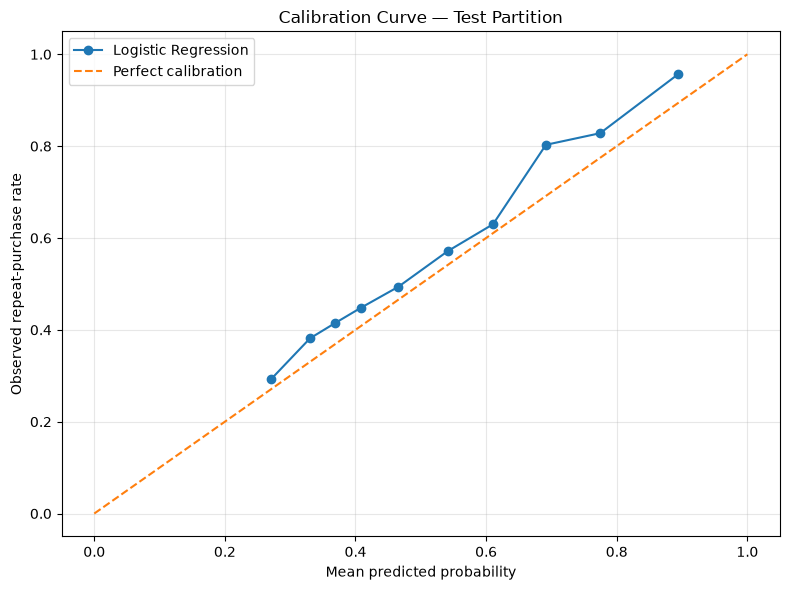

In [4]:
import matplotlib.pyplot as plt

# Calculate calibration points using 10 quantile-based bins
observed_rates, mean_predicted_rates = calibration_curve(
    y_test,
    test_probabilities,
    n_bins=10,
    strategy="quantile"
)

calibration_df = pd.DataFrame({
    "mean_predicted_probability": mean_predicted_rates,
    "observed_repeat_purchase_rate": observed_rates,
})

print("Calibration results:")
print(calibration_df.to_string(index=False))

# Plot calibration curve
plt.figure(figsize=(8, 6))

plt.plot(
    mean_predicted_rates,
    observed_rates,
    marker="o",
    label="Logistic Regression"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed repeat-purchase rate")
plt.title("Calibration Curve — Test Partition")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
# Extract coefficients from the fitted pipeline
logistic_model = selected_model.named_steps["logistic_regression"]

coefficient_df = pd.DataFrame({
    "feature": feature_columns,
    "standardized_coefficient": logistic_model.coef_[0],
})

coefficient_df["odds_ratio"] = np.exp(
    coefficient_df["standardized_coefficient"]
)

coefficient_df["direction"] = np.where(
    coefficient_df["standardized_coefficient"] > 0,
    "Positive",
    "Negative"
)

coefficient_df["absolute_coefficient"] = (
    coefficient_df["standardized_coefficient"].abs()
)

coefficient_df = coefficient_df.sort_values(
    "absolute_coefficient",
    ascending=False
).reset_index(drop=True)

print("Logistic Regression Coefficients and Odds Ratios:")
print(
    coefficient_df[
        [
            "feature",
            "standardized_coefficient",
            "odds_ratio",
            "direction",
        ]
    ].to_string(index=False)
)

Logistic Regression Coefficients and Odds Ratios:
                 feature  standardized_coefficient  odds_ratio direction
         log1p_frequency                    0.5922      1.8080  Positive
          log1p_monetary                    0.2601      1.2971  Positive
   log1p_unique_products                    0.1737      1.1897  Positive
            recency_days                   -0.0886      0.9152  Negative
log1p_cancellation_value                    0.0481      1.0493  Positive


In [6]:
# Create a test prediction analysis dataset
error_analysis_df = test_df[
    ["Customer ID", "snapshot_date"] + feature_columns + [target_column]
].copy()

error_analysis_df["predicted_probability"] = test_probabilities
error_analysis_df["predicted_class"] = test_predictions

# Classify prediction outcomes
error_analysis_df["prediction_outcome"] = np.select(
    [
        (error_analysis_df[target_column] == 1) &
        (error_analysis_df["predicted_class"] == 1),

        (error_analysis_df[target_column] == 0) &
        (error_analysis_df["predicted_class"] == 0),

        (error_analysis_df[target_column] == 0) &
        (error_analysis_df["predicted_class"] == 1),

        (error_analysis_df[target_column] == 1) &
        (error_analysis_df["predicted_class"] == 0),
    ],
    [
        "True Positive",
        "True Negative",
        "False Positive",
        "False Negative",
    ],
    default="Unknown"
)

# Summarize prediction outcomes
print("Prediction outcome counts:")
print(
    error_analysis_df["prediction_outcome"]
    .value_counts()
)

# Compare feature distributions by prediction outcome
error_feature_summary = (
    error_analysis_df
    .groupby("prediction_outcome")[feature_columns]
    .agg(["median", "mean"])
    .round(4)
)

print("\nFeature distributions by prediction outcome:")
print(error_feature_summary)

# Compare predicted probabilities by outcome
probability_summary = (
    error_analysis_df
    .groupby("prediction_outcome")["predicted_probability"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(4)
)

print("\nPredicted probability distributions:")
print(probability_summary)

Prediction outcome counts:
prediction_outcome
True Positive     2114
True Negative     1630
False Negative    1106
False Positive     684
Name: count, dtype: int64

Feature distributions by prediction outcome:
                   recency_days         log1p_frequency        log1p_monetary  \
                         median    mean          median   mean         median   
prediction_outcome                                                              
False Negative          84.0000 85.2794          0.6931 0.7315         5.6593   
False Positive          38.0000 44.9035          1.0986 1.2675         6.5818   
True Negative          101.0000 95.7656          0.6931 0.7309         5.4394   
True Positive           26.0000 34.8851          1.3863 1.6006         7.0706   

                          log1p_unique_products         \
                     mean                median   mean   
prediction_outcome                                       
False Negative     5.5514                2.8332 

In [7]:
def evaluate_partition(model, X, y, threshold=0.50):
    probabilities = model.predict_proba(X)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y, predictions, labels=[0, 1]
    ).ravel()

    return {
        "observations": len(y),
        "positive_rate": y.mean(),
        "roc_auc": roc_auc_score(y, probabilities),
        "pr_auc": average_precision_score(y, probabilities),
        "accuracy": accuracy_score(y, predictions),
        "precision": precision_score(y, predictions, zero_division=0),
        "recall": recall_score(y, predictions, zero_division=0),
        "specificity": tn / (tn + fp),
        "f1": f1_score(y, predictions, zero_division=0),
        "brier_score": brier_score_loss(y, probabilities),
    }


# Evaluate the same fitted model on all three partitions
partition_results = {
    "Train": evaluate_partition(
        selected_model, X_train, y_train
    ),
    "Validation": evaluate_partition(
        selected_model, X_validation, y_validation
    ),
    "Test": evaluate_partition(
        selected_model, X_test, y_test
    ),
}

generalization_df = pd.DataFrame(partition_results).T

print("Model performance across temporal partitions:")
print(generalization_df.round(4))

Model performance across temporal partitions:
            observations  positive_rate  roc_auc  pr_auc  accuracy  precision  \
Train        17,119.0000         0.5451   0.7267  0.7732    0.6670     0.7016   
Validation    9,985.0000         0.4196   0.7472  0.7190    0.6661     0.5826   
Test          5,534.0000         0.5819   0.7413  0.8139    0.6765     0.7555   

            recall  specificity     f1  brier_score  
Train       0.6771       0.6548 0.6891       0.2088  
Validation  0.7203       0.6269 0.6442       0.2116  
Test        0.6565       0.7044 0.7026       0.2031  


In [8]:
# Final evaluation summary
final_evaluation_summary = pd.DataFrame([
    {
        "metric": metric,
        "train": generalization_df.loc["Train", metric],
        "validation": generalization_df.loc["Validation", metric],
        "test": generalization_df.loc["Test", metric],
    }
    for metric in [
        "roc_auc",
        "pr_auc",
        "accuracy",
        "precision",
        "recall",
        "specificity",
        "f1",
        "brier_score",
    ]
])

# Final test confusion matrix
final_confusion_matrix = pd.DataFrame(
    {
        "predicted_0": [tn, fn],
        "predicted_1": [fp, tp],
    },
    index=["actual_0", "actual_1"]
)

print("Final evaluation summary:")
print(final_evaluation_summary.to_string(index=False))

print("\nFinal test confusion matrix:")
print(final_confusion_matrix)

Final evaluation summary:
     metric  train  validation   test
    roc_auc 0.7267      0.7472 0.7413
     pr_auc 0.7732      0.7190 0.8139
   accuracy 0.6670      0.6661 0.6765
  precision 0.7016      0.5826 0.7555
     recall 0.6771      0.7203 0.6565
specificity 0.6548      0.6269 0.7044
         f1 0.6891      0.6442 0.7026
brier_score 0.2088      0.2116 0.2031

Final test confusion matrix:
          predicted_0  predicted_1
actual_0         1630          684
actual_1         1106         2114
